
# 08 — Evaluación de hipótesis y análisis avanzado

## Objetivo

Consolidar y evaluar las tres hipótesis del proyecto de identificación de oportunidades inmobiliarias en CABA, utilizando los resultados obtenidos en las notebooks anteriores.

Se busca determinar qué hipótesis están respaldadas por la evidencia, evaluar la magnitud y robustez de los resultados y reconocer las limitaciones del análisis.

## Hipótesis a evaluar

- **H1 — Descuento por necesidad de refacción:** las propiedades que necesitan obra presentan precios inferiores a los de propiedades comparables.
- **H2 — Dispersión y oportunidades:** las zonas con mayor dispersión de precios presentan una mayor proporción de propiedades potencialmente subvaluadas.
- **H3 — Viabilidad económica del flipping:** algunas propiedades identificadas como oportunidades mantienen una rentabilidad positiva después de considerar costos de compra, refacción, tenencia y venta.

## Metodología

Se utilizarán los indicadores, análisis estadísticos, validaciones y escenarios económicos desarrollados en las notebooks 03 a 07.

Cada hipótesis será evaluada considerando evidencia cuantitativa, relevancia práctica, robustez y limitaciones.



### Procedencia de los resultados estadísticos

Las pruebas estadísticas correspondientes a H1 y H2 fueron realizadas originalmente en la notebook `04_analisis_hipotesis.ipynb`.

En esta notebook se recuperan y consolidan sus resultados para interpretarlos junto con la evaluación económica desarrollada en la notebook 07.

Por lo tanto, los valores de los estadísticos, los p-valores y las comparaciones de grupos de H1 y H2 corresponden a análisis previamente ejecutados, y no a nuevas pruebas realizadas en esta notebook.

En cambio, el análisis de H3, la evaluación de escenarios y el análisis de sensibilidad utilizan los archivos procesados generados por el modelo económico.



## 1. Hipótesis H1 — Descuento por necesidad de refacción

**Hipótesis:** las propiedades clasificadas como `Necesita_obra` presentan precios inferiores a los de propiedades comparables que no requieren refacción.

### Enfoque de evaluación

Para evaluar esta hipótesis, utilizamos los resultados del análisis exploratorio de la notebook 04 y los indicadores construidos en la notebook 03.

La comparación debe considerar el precio relativo respecto del PER, para evitar interpretar diferencias de precio explicadas por ubicación, superficie u otras características como descuentos atribuibles a la necesidad de obra.

Se analizarán:

- La magnitud del descuento observado.
- La evidencia estadística de la diferencia entre grupos.
- La relevancia económica del resultado.
- Las limitaciones de la clasificación del estado y del PER.


In [4]:

import pandas as pd

# Resultados obtenidos en la notebook 04 — EDA
# Se consolidan aquí sin volver a ejecutar los tests.

resultados_h1 = pd.DataFrame({
    "Comparación": [
        "Directa: USD/m²",
        "Controlada: precio relativo al PER"
    ],
    "Grupo": [
        "Necesita obra vs. reciclada",
        "Necesita obra vs. buen estado o reciclada"
    ],
    "N_necesita_obra": [439, 435],
    "N_comparacion": [977, 3010],
    "Mediana_necesita_obra": [1665.43, -17.41],
    "Mediana_comparacion": [2232.21, 0.04],
    "Diferencia": [-25.40, -17.50],
    "Unidad_diferencia": ["%", "puntos porcentuales"],
    "Test": ["Mann-Whitney", "Mann-Whitney"],
    "p_valor": ["< 0.001", "< 0.001"]
})

display(resultados_h1)


,Comparación,Grupo,N_necesita_obra,N_comparacion,Mediana_necesita_obra,Mediana_comparacion,Diferencia,Unidad_diferencia,Test,p_valor
0,Directa: USD/m²,Necesita obra vs. reciclada,439,977,1665.43,2232.21,-25.4,%,Mann-Whitney,< 0.001
1,Controlada: precio relativo al PER,Necesita obra vs. buen estado o reciclada,435,3010,-17.41,0.04,-17.5,puntos porcentuales,Mann-Whitney,< 0.001



### Interpretación de resultados — H1

Los resultados de la notebook 04 muestran que las propiedades clasificadas como `Necesita_obra` presentan precios inferiores a los de las propiedades en mejor estado.

En la comparación directa, el precio mediano por m² es un **25,4% menor** que el de las propiedades recicladas.

Al utilizar el precio relativo al PER, la diferencia entre las medianas es de aproximadamente **17,5 puntos porcentuales**, lo que indica que el descuento persiste incluso al comparar los inmuebles con una referencia de mercado construida a partir de características similares.

Ambas comparaciones presentan diferencias estadísticamente significativas (Mann-Whitney, p < 0,001).

**Conclusión H1: respaldada por la evidencia.**

Los resultados son consistentes con la existencia de un descuento asociado a la necesidad de refacción. Sin embargo, no permiten afirmar causalidad, ya que pueden existir características no observadas que también influyan en el precio.

Además, el PER es una estimación basada en precios publicados, no en precios efectivos de cierre.



## 2. Hipótesis H2 — Dispersión de precios y oportunidades

**Hipótesis:** las zonas con mayor dispersión de precios presentan una mayor proporción de propiedades potencialmente subvaluadas.

### Enfoque de evaluación

Para evaluar esta hipótesis, recuperamos los resultados de la notebook 04, donde se analiza la relación entre la dispersión de precios y la proporción de propiedades identificadas como oportunidades.

Se utiliza la correlación de Spearman, que permite evaluar si existe una asociación monotónica entre ambas variables sin exigir una relación lineal.

El análisis considera:

- La dirección y magnitud de la correlación.
- La significancia estadística.
- La relevancia del resultado para identificar zonas de búsqueda.
- Las limitaciones de utilizar precios publicados y oportunidades definidas a partir del PER.

La existencia de una correlación positiva no implica que la dispersión cause oportunidades de inversión ni que todas las propiedades de una zona dispersa estén subvaluadas.


In [5]:

import pandas as pd

# Resultados de H2 obtenidos en la notebook 04 — EDA
resultados_h2 = pd.DataFrame({
    "Indicador": [
        "Correlación de Spearman",
        "p-valor",
        "Dirección de la relación"
    ],
    "Resultado": [
        "0.48",
        "< 0.001",
        "Positiva"
    ]
})

display(resultados_h2)


,Indicador,Resultado
0,Correlación de Spearman,0.48
1,p-valor,< 0.001
2,Dirección de la relación,Positiva



### Interpretación de resultados — H2

Los resultados de la notebook 04 muestran una **correlación positiva moderada** entre la dispersión de precios y la proporción de propiedades potencialmente subvaluadas (Spearman ρ = 0,48).

La asociación es estadísticamente significativa (p < 0,001), lo que aporta evidencia a favor de la hipótesis.

Desde el punto de vista del negocio, esto sugiere que las zonas con mayor dispersión pueden ser interesantes para priorizar la búsqueda de oportunidades inmobiliarias.

Sin embargo, la correlación no implica causalidad. Además, una propiedad identificada como barata respecto del PER no necesariamente representa una oportunidad rentable después de considerar los costos de refacción y operación.

**Conclusión H2: respaldada por la evidencia, con limitaciones.**

La dispersión de precios puede utilizarse como criterio complementario de búsqueda, pero no como indicador suficiente para recomendar una inversión.



## 3. Hipótesis H3 — Viabilidad económica del flipping

**Hipótesis:** algunas propiedades identificadas como oportunidades inmobiliarias mantienen una rentabilidad positiva después de considerar los costos asociados a una operación de compra, refacción y reventa.

### Enfoque de evaluación

Para evaluar esta hipótesis, utilizamos el modelo económico desarrollado en la notebook 07.

El análisis comprende **428 propiedades clasificadas como `Necesita_obra`**, evaluadas mediante tres escenarios:

- **Conservador:** PER conservador y refacción de 500 USD/m².
- **Base:** PER base y refacción de 300 USD/m².
- **Optimista:** PER optimista y refacción de 150 USD/m².

En todos los escenarios se consideran gastos de compra, gastos de venta, expensas y un período de tenencia de seis meses.

### Criterio de evaluación

Se considera que una propiedad presenta **robustez económica** cuando obtiene un ROI positivo en los tres escenarios.

También se analizarán las diferencias de rentabilidad entre escenarios, las alertas de revisión y las limitaciones de los supuestos económicos.

Los resultados representan simulaciones basadas en precios publicados y costos estimados, no rentabilidades efectivamente realizadas.


In [6]:

import pandas as pd

# Cargar resultados de la notebook 07
df_economico = pd.read_csv(
    "data/processed/flipping_modelo_economico.csv"
)

df_oportunidades = pd.read_csv(
    "data/processed/flipping_ranking_priorizado.csv"
)

# Resumen de rentabilidad por escenario
escenarios = ["Conservador", "Base", "Optimista"]

resumen_h3 = pd.DataFrame([
    {
        "Escenario": escenario,
        "Propiedades rentables": (
            df_economico[f"ROI_{escenario}_pct"] > 0
        ).sum(),
        "Porcentaje rentable": round(
            (df_economico[f"ROI_{escenario}_pct"] > 0).mean() * 100, 2
        ),
        "ROI mediano (%)": round(
            df_economico[f"ROI_{escenario}_pct"].median(), 2
        )
    }
    for escenario in escenarios
])

print("Propiedades evaluadas:", len(df_economico))
display(resumen_h3)

print("\nOportunidades rentables en los tres escenarios:",
      len(df_oportunidades))

print("\nClasificación de prioridad:")
display(
    df_oportunidades["Prioridad_Analisis"]
    .value_counts()
    .rename_axis("Prioridad")
    .reset_index(name="Cantidad")
)


Propiedades evaluadas: 428


,Escenario,Propiedades rentables,Porcentaje rentable,ROI mediano (%)
0,Conservador,46,10.75,-21.46
1,Base,190,44.39,-2.94
2,Optimista,340,79.44,18.20



Oportunidades rentables en los tres escenarios: 46

Clasificación de prioridad:


,Prioridad,Cantidad
0,Prioridad de análisis,24
1,Revisión adicional,22



### Interpretación de resultados — H3

El modelo económico evaluó **428 propiedades que necesitan refacción**, considerando los costos de compra, obra, tenencia y venta.

Los resultados muestran diferencias importantes entre escenarios:

- **Conservador:** 46 propiedades rentables (10,75%), con un ROI mediano de -21,46%.
- **Base:** 190 propiedades rentables (44,39%), con un ROI mediano de -2,94%.
- **Optimista:** 340 propiedades rentables (79,44%), con un ROI mediano de 18,20%.

Esto evidencia que la rentabilidad es sensible a los costos de refacción y al precio estimado de reventa.

Sin embargo, **46 propiedades mantienen un ROI positivo en los tres escenarios**, lo que representa un 10,75% de las propiedades evaluadas.

Dentro de estas oportunidades, 24 fueron clasificadas como `Prioridad de análisis` y 22 como `Revisión adicional`, debido a las alertas identificadas.

### Conclusión H3

**Hipótesis respaldada bajo los supuestos del modelo económico.**

Los resultados sugieren que existen oportunidades potencialmente rentables incluso bajo condiciones conservadoras. No obstante, la mayoría de las propiedades presenta rentabilidad negativa en ese escenario.

La rentabilidad estimada no garantiza ganancias reales. Los resultados dependen de los precios publicados, la calidad del PER y los costos asumidos, que deberán verificarse antes de realizar una inversión.

Las 24 propiedades priorizadas constituyen candidatos para una evaluación más detallada, no recomendaciones de compra definitivas.



## 4. Análisis de sensibilidad económica

El objetivo es evaluar qué tan sensibles son las oportunidades de flipping a cambios en dos variables importantes:

- **Costo de refacción:** aumentos del 10% y 20% respecto del escenario conservador.
- **Precio de reventa:** reducciones del 5% y 10% respecto del PER conservador.

Se utiliza el escenario conservador como punto de partida para evaluar condiciones más desfavorables.

El análisis se aplica a las 46 propiedades inicialmente rentables en los tres escenarios, manteniendo constantes los demás supuestos.

Se evaluará cuántas propiedades continúan presentando ROI positivo y cómo cambia su rentabilidad mediana.


In [7]:

import pandas as pd

# Partimos de las 46 propiedades robustas
df_sensibilidad = df_economico.loc[
    df_economico["Robustez_Economica"]
    == "Rentable en los tres escenarios"
].copy()

resultados_sensibilidad = []

# Variaciones respecto del escenario conservador
for aumento_obra in [0, 0.10, 0.20]:
    for caida_reventa in [0, 0.05, 0.10]:

        # Inversión ajustada por aumento de obra
        inversion = (
            df_sensibilidad["Inversion_Total_Conservador_USD"]
            + df_sensibilidad["Refaccion_Conservador_USD"]
            * aumento_obra
        )

        # Valor de reventa ajustado
        reventa = (
            df_sensibilidad["PER_Conservador"]
            * (1 - caida_reventa)
        )

        # Gastos de venta proporcionales al precio de reventa
        tasa_gastos_venta = 0.03
        ganancia = (
            reventa * (1 - tasa_gastos_venta)
            - inversion
        )

        roi = ganancia / inversion * 100

        resultados_sensibilidad.append({
            "Aumento obra (%)": aumento_obra * 100,
            "Caída reventa (%)": caida_reventa * 100,
            "Rentables": int((roi > 0).sum()),
            "Porcentaje rentable": round(
                (roi > 0).mean() * 100, 2
            ),
            "ROI mediano (%)": round(roi.median(), 2)
        })

tabla_sensibilidad = pd.DataFrame(
    resultados_sensibilidad
)

display(tabla_sensibilidad)


,Aumento obra (%),Caída reventa (%),Rentables,Porcentaje rentable,ROI mediano (%)
0,0.0,0.0,46,100.00,3.78
1,0.0,5.0,19,41.30,-1.41
2,0.0,10.0,13,28.26,-6.60
3,10.0,0.0,26,56.52,1.27
4,10.0,5.0,14,30.43,-3.80
5,10.0,10.0,7,15.22,-8.86
6,20.0,0.0,20,43.48,-1.33
7,20.0,5.0,12,26.09,-6.26
8,20.0,10.0,6,13.04,-11.19


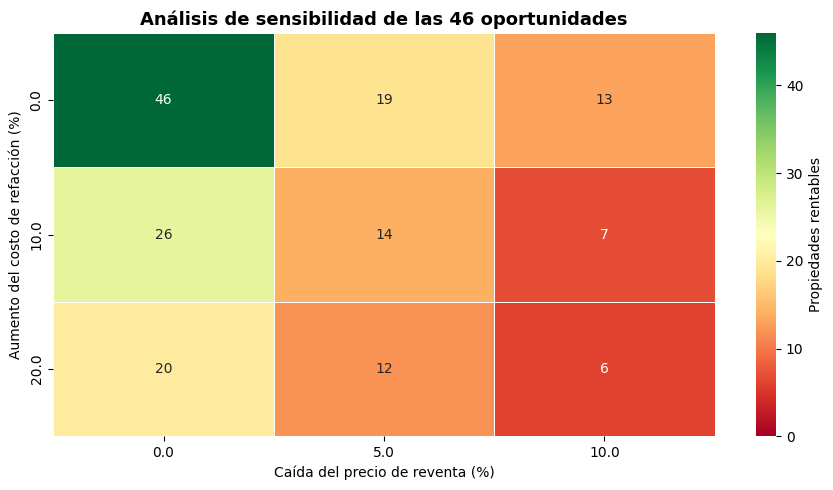

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

# Crear matriz para visualizar la sensibilidad
matriz = tabla_sensibilidad.pivot(
    index="Aumento obra (%)",
    columns="Caída reventa (%)",
    values="Rentables"
)

plt.figure(figsize=(9, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt=".0f",
    cmap="RdYlGn",
    vmin=0,
    vmax=46,
    linewidths=0.5,
    cbar_kws={"label": "Propiedades rentables"}
)

plt.title(
    "Análisis de sensibilidad de las 46 oportunidades",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Caída del precio de reventa (%)")
plt.ylabel("Aumento del costo de refacción (%)")

plt.tight_layout()
plt.show()



### Interpretación del análisis de sensibilidad

El análisis muestra que las 46 oportunidades identificadas inicialmente presentan una sensibilidad considerable a los cambios en los costos de refacción y en el precio de reventa.

En el escenario conservador original, las 46 propiedades mantienen un ROI positivo, aunque la rentabilidad mediana es de apenas **3,78%**.

Cuando el precio de reventa disminuye un 5%, solamente 19 propiedades (41,30%) continúan siendo rentables. Si el costo de refacción aumenta un 20%, permanecen rentables 20 propiedades (43,48%).

En el escenario más desfavorable, combinando un aumento del 20% en los costos de obra con una caída del 10% en el precio de reventa, **solo 6 propiedades (13,04%) mantienen un ROI positivo**.

### Conclusión

Aunque existen oportunidades potencialmente rentables, muchas presentan márgenes reducidos y dependen de que se cumplan los supuestos económicos.

Por lo tanto, el ranking original debe utilizarse como una herramienta de preselección y no como una recomendación definitiva de inversión.

El análisis de sensibilidad permite identificar la necesidad de incorporar márgenes de seguridad y verificar los costos y precios de cada operación antes de tomar decisiones.


In [8]:

import numpy as np

# Recalcular el ROI sin modificar ningún supuesto
inversion_original = df_sensibilidad[
    "Inversion_Total_Conservador_USD"
]

reventa_original = df_sensibilidad["PER_Conservador"]

roi_recalculado = (
    (reventa_original * (1 - 0.03) - inversion_original)
    / inversion_original
) * 100

# Comparar contra el ROI guardado en la notebook 07
roi_modelo = df_sensibilidad["ROI_Conservador_pct"]

diferencia = (roi_recalculado - roi_modelo).abs()

print("Propiedades comparadas:", len(diferencia))
print("Diferencia máxima de ROI (puntos porcentuales):",
      round(diferencia.max(), 8))
print("Diferencia media:", round(diferencia.mean(), 8))

print(
    "¿Coinciden los cálculos?",
    np.allclose(roi_recalculado, roi_modelo, atol=1e-6)
)


Propiedades comparadas: 46
Diferencia máxima de ROI (puntos porcentuales): 0.0
Diferencia media: 0.0
¿Coinciden los cálculos? True


In [9]:

# Consolidación de las hipótesis del proyecto

resumen_hipotesis = pd.DataFrame({
    "Hipótesis": ["H1", "H2", "H3"],
    "Pregunta": [
        "¿Las propiedades que necesitan obra presentan descuentos?",
        "¿La dispersión de precios se relaciona con las oportunidades?",
        "¿Existen oportunidades rentables después de considerar los costos?"
    ],
    "Evidencia principal": [
        "Descuento relativo al PER de 17,5 pp; p < 0,001",
        "Spearman = 0,48; p < 0,001",
        "46 de 428 propiedades rentables en los tres escenarios"
    ],
    "Conclusión": [
        "Respaldada estadísticamente",
        "Respaldada estadísticamente",
        "Respaldada bajo los supuestos económicos"
    ],
    "Limitación principal": [
        "Clasificación del estado y variables no observadas",
        "Correlación no implica causalidad",
        "Alta sensibilidad a costos y precios de reventa"
    ]
})

display(resumen_hipotesis)


,Hipótesis,Pregunta,Evidencia principal,Conclusión,Limitación principal
0,H1,¿Las propiedades que necesitan obra presentan ...,"Descuento relativo al PER de 17,5 pp; p < 0,001",Respaldada estadísticamente,Clasificación del estado y variables no observ...
1,H2,¿La dispersión de precios se relaciona con las...,"Spearman = 0,48; p < 0,001",Respaldada estadísticamente,Correlación no implica causalidad
2,H3,¿Existen oportunidades rentables después de co...,46 de 428 propiedades rentables en los tres es...,Respaldada bajo los supuestos económicos,Alta sensibilidad a costos y precios de reventa



## 5. Conclusiones generales

El análisis realizado aporta evidencia favorable a las tres hipótesis del proyecto, aunque con distintos niveles de respaldo.

**H1 — Descuento por necesidad de refacción**

Las propiedades que necesitan obra presentan precios inferiores a los de propiedades comparables. La diferencia es estadísticamente significativa y persiste al utilizar el PER como referencia de mercado.

**H2 — Dispersión y oportunidades**

Se identifica una asociación positiva moderada entre la dispersión de precios y la proporción de propiedades potencialmente subvaluadas. Esto permite utilizar la dispersión como criterio complementario para orientar la búsqueda de oportunidades.

**H3 — Viabilidad económica del flipping**

De las 428 propiedades evaluadas, 46 presentan rentabilidad positiva en los tres escenarios económicos. Sin embargo, el análisis de sensibilidad muestra que muchas oportunidades tienen márgenes reducidos: ante un aumento del 20% en los costos de refacción y una caída del 10% en el precio de reventa, solamente 6 mantienen un ROI positivo.

### Implicancias para la toma de decisiones

Los resultados permiten construir un proceso de identificación y priorización de oportunidades inmobiliarias basado en datos.

El PER funciona como referencia inicial para detectar posibles descuentos, mientras que el modelo económico permite evaluar si esos descuentos podrían traducirse en rentabilidad después de considerar los costos.

El ranking resultante debe interpretarse como una herramienta de preselección. Antes de recomendar una inversión es necesario verificar el estado real del inmueble, los costos de obra, las condiciones comerciales y el precio probable de cierre.

### Limitaciones

- Los precios utilizados son valores publicados, no precios efectivos de compraventa.
- La clasificación del estado del inmueble se basa en información de los avisos.
- El PER presenta error de estimación y cobertura variable según los comparables disponibles.
- Los costos económicos son supuestos de simulación.
- Los resultados representan asociaciones y escenarios estimados, no relaciones causales ni rentabilidades garantizadas.

En conjunto, el proyecto demuestra la utilidad de combinar análisis estadístico, indicadores de mercado y simulaciones económicas para mejorar la selección inicial de oportunidades de flipping en CABA.
